# Article1 figures

Figures and text for the first LinkedIn article (all products).

Cells are the original session code in execution order (exported verbatim; only secrets handling and artifact paths were changed). Each cell starts with a comment giving its original index, conda environment and run status. Exploratory and failed cells are kept, so later cells that rely on their partial state still make sense.


In [ ]:
# Setup: run from the repository root; helper modules live in prod/
import os, sys
if os.path.basename(os.getcwd())=='notebooks': os.chdir('..')
sys.path.insert(0, 'prod')
os.makedirs('out', exist_ok=True)
from style import apply_figure_style  # stand-in for the figure style used in the session


In [176]:
# [orig cell 175 | env: precip | status: ok]
import numpy as np, pandas as pd, requests, gzip, eccodes, xarray as xr, h5py, glob, os, json
sid_lat,sid_lon=25.788,-80.317
def grib(b):
    if b[:2]==b'\x1f\x8b': b=gzip.decompress(b)
    g=eccodes.codes_new_from_message(b); ni=eccodes.codes_get(g,'Ni'); nj=eccodes.codes_get(g,'Nj')
    v=eccodes.codes_get_values(g).reshape(nj,ni).astype(np.float32); mv=eccodes.codes_get(g,'missingValue')
    la=eccodes.codes_get_array(g,'latitudes').reshape(nj,ni); lo=eccodes.codes_get_array(g,'longitudes').reshape(nj,ni); eccodes.codes_release(g)
    lo=np.where(lo>180,lo-360,lo); v[(v==mv)|(v<0)]=np.nan; return v,la,lo
F={}
# MRMS gauge-corrected, hour 22-23 UTC (file stamped 23:00)
r=requests.get('https://mtarchive.geol.iastate.edu/2020/05/26/mrms/ncep/GaugeCorr_QPE_01H/GaugeCorr_QPE_01H_00.00_20200526-230000.grib2.gz',timeout=120)
v,la,lo=grib(r.content); m=(la>25.2)&(la<26.4)&(lo>-80.9)&(lo<-79.7); ii,jj=np.where(m)
F['mrms']=(v[ii.min():ii.max()+1,jj.min():jj.max()+1],la[ii.min():ii.max()+1,jj.min():jj.max()+1],lo[ii.min():ii.max()+1,jj.min():jj.max()+1]); del v,la,lo
r=requests.get('https://mesonet.agron.iastate.edu/archive/data/2020/05/26/stage4/ST4.2020052623.01h.grib',timeout=120)
v,la,lo=grib(r.content); m=(la>25.0)&(la<26.6)&(lo>-81.1)&(lo<-79.5); ii,jj=np.where(m)
F['stage4']=(v[ii.min():ii.max()+1,jj.min():jj.max()+1],la[ii.min():ii.max()+1,jj.min():jj.max()+1],lo[ii.min():ii.max()+1,jj.min():jj.max()+1])
def imf(t):
    e=t+pd.Timedelta(minutes=29,seconds=59)
    fn=f"prod/imerg/3B-HHR.MS.MRG.3IMERG.{t:%Y%m%d}-S{t:%H%M%S}-E{e:%H%M%S}.{t.hour*60+t.minute:04d}.V07B.HDF5.nc4"
    with h5py.File(fn,'r') as f: x=f['Grid/precipitation'][0].astype(np.float32).T
    x[x<0]=np.nan; return x
ref=xr.open_dataset('imerg_test.nc4',group='Grid'); ila,ilo=np.meshgrid(ref.lat.values,ref.lon.values,indexing='ij')
F['imerg']=((imf(pd.Timestamp('2020-05-26 22:00'))+imf(pd.Timestamp('2020-05-26 22:30')))/2,ila,ilo)
z=np.load('prod/era5/era5_edh.npz'); vt=pd.DatetimeIndex(z['vt']); k=vt.get_loc(pd.Timestamp('2020-05-26 23:00'))
ela,elo=np.meshgrid(z['lat'],z['lon'],indexing='ij'); F['era5']=(z['tp'][k]*1000,ela,elo)
for kk,(v,la,lo) in F.items():
    d=(la-sid_lat)**2+((lo-sid_lon)*0.9)**2; i,j=np.unravel_index(np.nanargmin(d),d.shape)
    print(kk,v.shape,'station pixel',round(float(v[i,j]),1),'max within ~25 km',round(float(np.nanmax(np.where(d<(0.23)**2,v,np.nan))),1))

mrms (120, 120) station pixel 48.7 max within ~25 km 67.7
stage4 (62, 60) station pixel 54.8 max within ~25 km 77.2
imerg (85, 97) station pixel 4.6 max within ~25 km 16.0
era5 (39, 45) station pixel 3.5 max within ~25 km 5.0


In [177]:
# [orig cell 176 | env: precip | status: ok]
import matplotlib as mpl, matplotlib.pyplot as plt, cartopy, cartopy.crs as ccrs, cartopy.feature as cfeat
cartopy.config['data_dir']=os.path.abspath('cartopy_data')
try: apply_figure_style(); print('style')
except NameError: pass
mpl.rcParams.update({'font.size':11,'axes.titlesize':12,'font.family':'DejaVu Sans'})
ext=[-80.75,-79.88,25.38,26.2]
cmap=mpl.colormaps['YlGnBu'].copy(); cmap.set_under('white'); norm=mpl.colors.BoundaryNorm([1,5,10,20,30,40,50,60,70,85],cmap.N,extend='max')
panels=[('mrms','MRMS radar + gauge\n1 km pixels'),('stage4','Stage IV radar + gauge\n4 km pixels'),('imerg','IMERG satellite\n10 km pixels'),('era5','ERA5 reanalysis\n25 km pixels')]
fig,axs=plt.subplots(1,4,figsize=(15,4.9),subplot_kw=dict(projection=ccrs.PlateCarree()),gridspec_kw=dict(wspace=0.06))
for ax,(k,ttl) in zip(axs,panels):
    v,la,lo=F[k]
    d=(la-sid_lat)**2+((lo-sid_lon)*0.9)**2; i,j=np.unravel_index(np.nanargmin(d),d.shape); sv=v[i,j]
    if k in ('imerg','era5'):   # regular grids: draw cells as blocks
        im=ax.pcolormesh(lo,la,v,cmap=cmap,norm=norm,shading='nearest',transform=ccrs.PlateCarree())
    else:
        im=ax.pcolormesh(lo,la,v,cmap=cmap,norm=norm,shading='auto',transform=ccrs.PlateCarree())
    ax.add_feature(cfeat.COASTLINE.with_scale('10m'),lw=0.8,edgecolor='0.25')
    ax.set_extent(ext,crs=ccrs.PlateCarree())
    ax.plot(sid_lon,sid_lat,marker='*',ms=17,mfc='#e6550d',mec='k',mew=0.8,transform=ccrs.PlateCarree(),zorder=5)
    ax.set_title(ttl,loc='left',fontsize=11)
    ax.text(0.03,0.04,f'{sv:.0f} mm' if sv>=1 else f'{sv:.1f} mm',transform=ax.transAxes,fontsize=17,fontweight='bold',color='k',
            bbox=dict(facecolor='white',edgecolor='none',alpha=0.85,pad=3))
cb=fig.colorbar(im,ax=axs,orientation='horizontal',fraction=0.05,pad=0.04,aspect=60,ticks=[1,5,10,20,30,40,50,60,70,85])
cb.set_label('rainfall in one hour (mm), 26 May 2020, 22–23 UTC',fontsize=11)
fig.suptitle('One hour over Miami: the rain gauge (★) recorded 84.6 mm. Number = what each product shows over the gauge.',x=0.125,ha='left',y=1.0,fontsize=13)
fig.savefig('out/li_fig1_miami.png',dpi=200,bbox_inches='tight')

~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)

                px_km  hit_N9_%  ratio_%
product                                 
mrms_gaugecorr    1.0      54.6     71.0
mrms_radaronly    1.0      53.3     63.0
stage4            3.8      66.3     62.0
nldas2           13.0      19.1     32.0
pccs              4.2       6.4     10.0
cmorph            7.6       3.0      9.0
imerg            10.4       2.2     10.0
era5             26.1       0.0      2.0
merra2           58.4       0.1      2.0


~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)

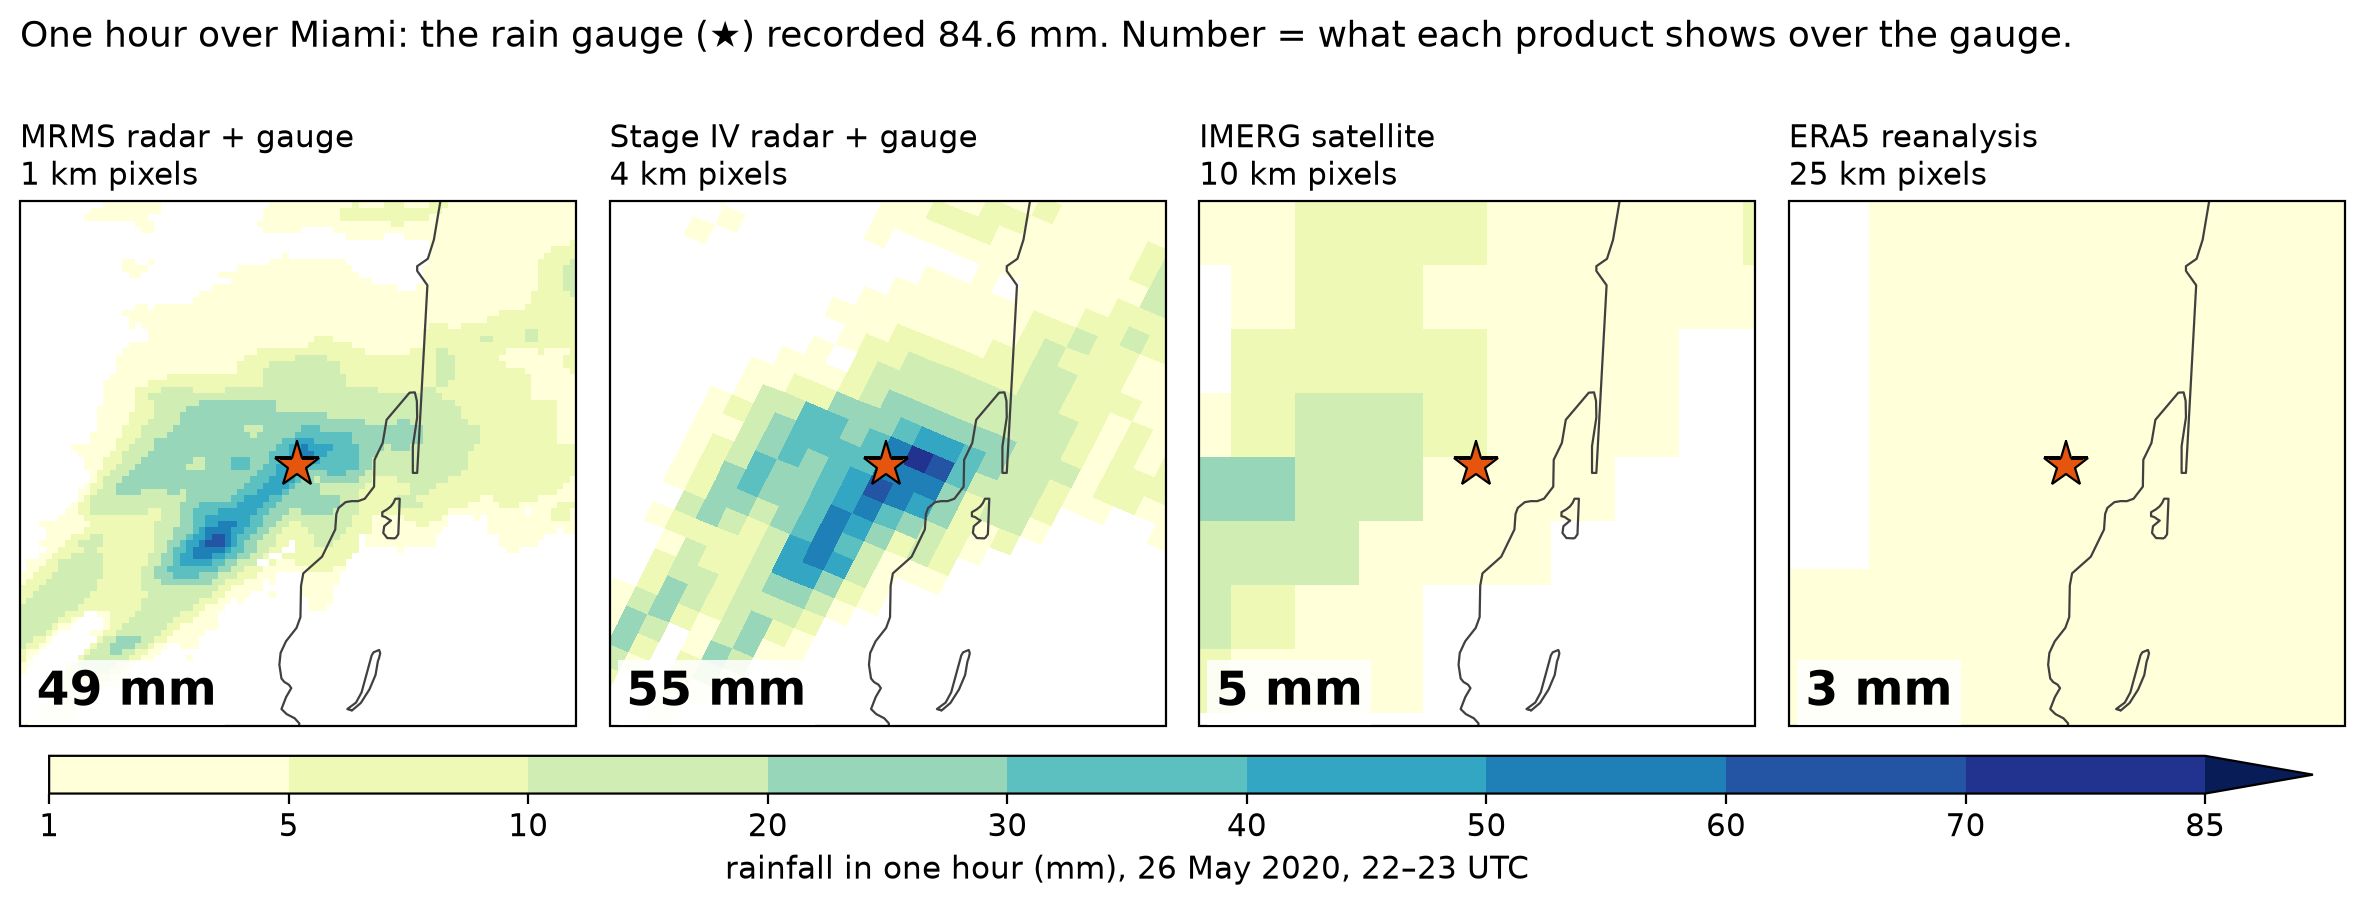

In [178]:
# [orig cell 177 | env: precip | status: ok]
fig._suptitle.set_y(0.9); fig.savefig('out/li_fig1_miami.png',dpi=200,bbox_inches='tight')
DS=pd.read_csv('out/detection_scores.csv'); ND=pd.read_csv('out/neighborhood_definitions.csv')
px=ND[ND.nbhd=='N1'].set_index('product').eval('sqrt(pixel_dx_km*pixel_dy_km)')
pc={'mrms_gaugecorr':'#08306b','mrms_radaronly':'#4292c6','stage4':'#2171b5','nldas2':'#41ab5d','pccs':'#fd8d3c','cmorph':'#e6550d','imerg':'#a63603','era5':'#6a51a3','merra2':'#737373'}
nice={'mrms_gaugecorr':'MRMS radar+gauge','mrms_radaronly':'MRMS radar-only','stage4':'Stage IV','nldas2':'NLDAS-2','pccs':'PERSIANN-CCS','cmorph':'CMORPH','imerg':'IMERG','era5':'ERA5','merra2':'MERRA-2'}
d30=DS[(DS.threshold==30)]
hit=d30[d30.nbhd=='N9'].set_index('product').hit_strict; ratio=d30[d30.nbhd=='N1'].set_index('product').ratio_median
fig2,ax=plt.subplots(1,2,figsize=(13,5.2),gridspec_kw=dict(wspace=0.28))
off={'mrms_gaugecorr':(8,6),'mrms_radaronly':(8,-14),'stage4':(8,-4),'nldas2':(8,4),'pccs':(-10,10),'cmorph':(8,-4),'imerg':(8,8),'era5':(8,6),'merra2':(-12,8)}
off2={'mrms_gaugecorr':(8,4),'mrms_radaronly':(8,-12),'stage4':(8,2),'nldas2':(8,4),'pccs':(-10,10),'cmorph':(8,-6),'imerg':(8,8),'era5':(8,6),'merra2':(-12,10)}
for a,ser,lab,o,fmtv in [(ax[0],hit*100,'% of ≥30 mm/h gauge events the product also reaches\n(3×3 pixels around the gauge)',off,'{:.0f}%'),(ax[1],ratio*100,'Share of the gauge peak the product shows\n(median, pixel over the gauge)',off2,'{:.0f}%')]:
    for p in nice:
        a.scatter(px[p],ser[p],s=110,color=pc[p],edgecolor='k',lw=0.6,zorder=3)
        ha='left' if o[p][0]>0 else 'right'
        a.annotate(nice[p],(px[p],ser[p]),xytext=o[p],textcoords='offset points',fontsize=10,ha=ha,va='center',color=pc[p] if p!='merra2' else '0.3')
    a.set_xscale('log'); a.set_xticks([1,4,10,25,60]); a.get_xaxis().set_major_formatter(mpl.ticker.FuncFormatter(lambda x,_:f'{x:g} km'))
    a.set_xlim(0.7,110); a.set_ylim(-4,104); a.set_ylabel(lab,fontsize=11); a.set_xlabel('pixel size (log scale)',fontsize=11)
    a.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(100)); a.grid(alpha=0.25)
ax[0].set_title('Bigger pixels: extremes disappear',loc='left',fontsize=13); ax[1].set_title('Even radar shows only 2/3 of the peak',loc='left',fontsize=13)
fig2.text(0.08,-0.04,'Blue = radar   •   Green = gauge/radar-based model forcing   •   Orange = satellite   •   Purple/grey = global reanalysis.   2,769 extreme hours at 79 Florida gauges, 2015–2025.',fontsize=9.5,color='0.3')
fig2.savefig('out/li_fig2_resolution.png',dpi=200,bbox_inches='tight')
print(pd.DataFrame({'px_km':px.round(1),'hit_N9_%':(hit*100).round(1),'ratio_%':(ratio*100).round(0)}).loc[list(nice)])

In [179]:
# [orig cell 178 | env: precip | status: ok]
off={'mrms_gaugecorr':(8,6),'mrms_radaronly':(8,-14),'stage4':(8,-4),'nldas2':(8,4),'pccs':(-10,10),'cmorph':(-6,-16),'imerg':(6,14),'era5':(-4,16),'merra2':(4,16)}
off2={'mrms_gaugecorr':(8,4),'mrms_radaronly':(8,-12),'stage4':(8,2),'nldas2':(8,4),'pccs':(-10,10),'cmorph':(8,-12),'imerg':(6,12),'era5':(-4,16),'merra2':(4,16)}
fig2,ax=plt.subplots(1,2,figsize=(13,5.2),gridspec_kw=dict(wspace=0.28))
for a,ser,lab,o in [(ax[0],hit*100,'% of ≥30 mm/h gauge events the product also reaches\n(3×3 pixels around the gauge)',off),(ax[1],ratio*100,'Share of the gauge peak the product shows\n(median, pixel over the gauge)',off2)]:
    for p in nice:
        a.scatter(px[p],ser[p],s=110,color=pc[p],edgecolor='k',lw=0.6,zorder=3)
        ha='left' if o[p][0]>0 else 'right'
        if p in('era5','merra2'): ha='right' if p=='era5' else 'left'
        a.annotate(nice[p],(px[p],ser[p]),xytext=o[p],textcoords='offset points',fontsize=10,ha=ha,va='center',color=pc[p] if p!='merra2' else '0.3')
    a.set_xscale('log'); a.set_xticks([1,4,10,25,60]); a.get_xaxis().set_major_formatter(mpl.ticker.FuncFormatter(lambda x,_:f'{x:g} km'))
    a.set_xlim(0.7,110); a.set_ylim(-4,104); a.set_ylabel(lab,fontsize=11); a.set_xlabel('pixel size (log scale)',fontsize=11)
    a.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(100)); a.grid(alpha=0.25)
ax[0].set_title('Coarser products miss the extremes',loc='left',fontsize=13); ax[1].set_title('Even radar shows only 62–71% of the peak',loc='left',fontsize=13)
fig2.text(0.08,-0.04,'Blue = radar   •   Green = gauge/radar-based model forcing   •   Orange = satellite   •   Purple/grey = global reanalysis.   2,769 extreme events at 79 Florida gauges, 2015–2025.',fontsize=9.5,color='0.3')
fig2.savefig('out/li_fig2_resolution.png',dpi=200,bbox_inches='tight')
r=fig2.canvas.get_renderer(); tx=[t for t in fig2.findobj(mpl.text.Text) if t.get_text().strip() and t.get_visible()]; bb=[t.get_window_extent(r) for t in tx]
print([(tx[i].get_text(),tx[j].get_text()) for i in range(len(bb)) for j in range(i+1,len(bb)) if bb[i].overlaps(bb[j])])

[('IMERG', 'ERA5'), ('IMERG', 'pixel size (log scale)'), ('−20%', 'Blue = radar   •   Green = gauge/radar-based model forcing   •   Orange = satellite   •   Purple/grey = global reanalysis.   2,769 extreme events at 79 Florida gauges, 2015–2025.'), ('CMORPH', 'ERA5'), ('IMERG', 'pixel size (log scale)'), ('ERA5', 'pixel size (log scale)'), ('−20%', 'Blue = radar   •   Green = gauge/radar-based model forcing   •   Orange = satellite   •   Purple/grey = global reanalysis.   2,769 extreme events at 79 Florida gauges, 2015–2025.')]


[('CMORPH', 'pixel size (log scale)'), ('CMORPH', 'pixel size (log scale)')]


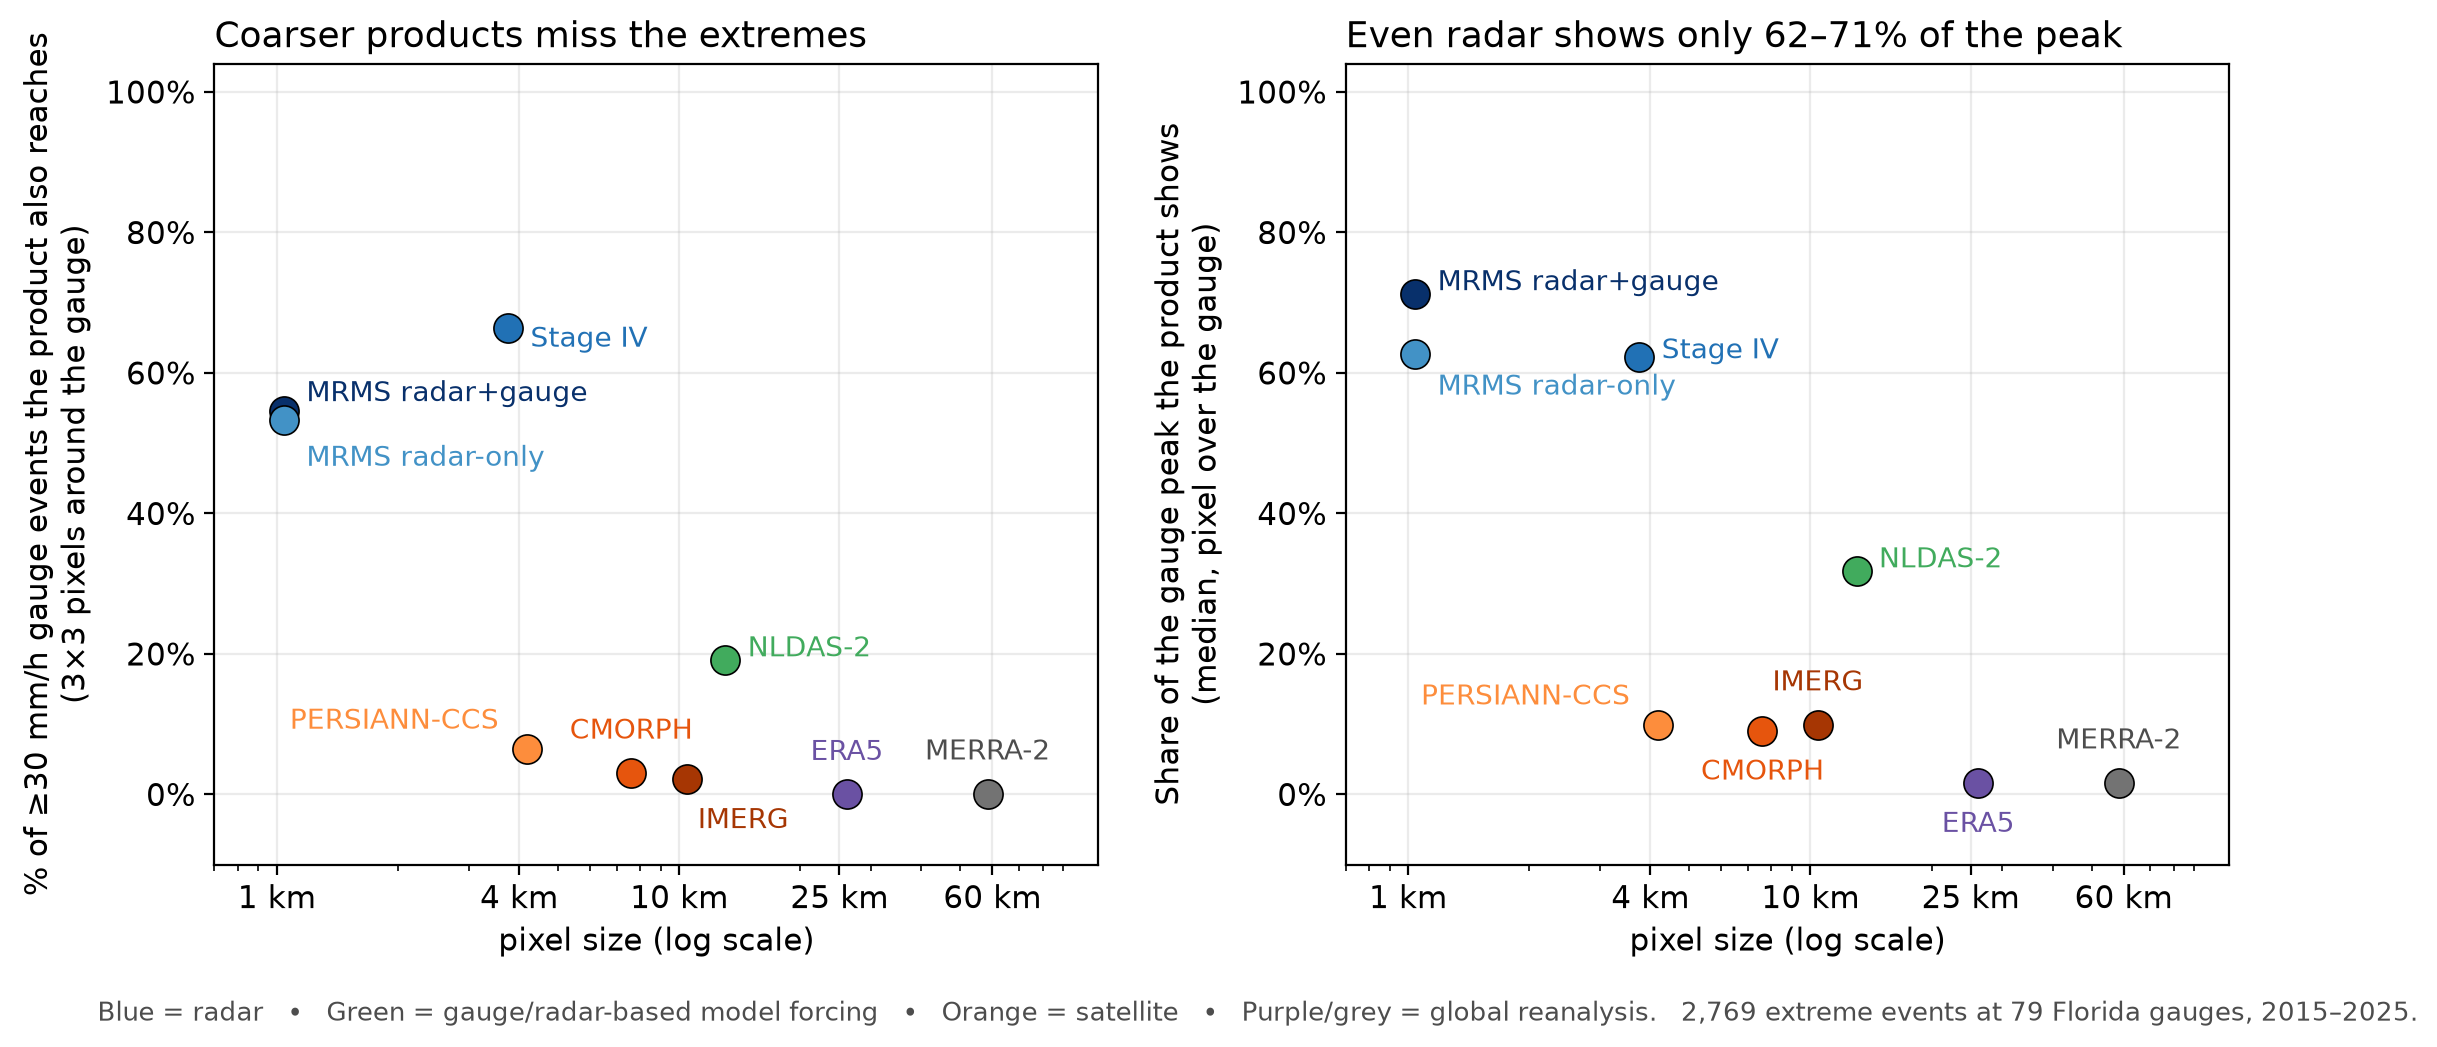

In [180]:
# [orig cell 179 | env: precip | status: ok]
off={'mrms_gaugecorr':(8,6),'mrms_radaronly':(8,-14),'stage4':(8,-4),'nldas2':(8,4),'pccs':(-10,10),'cmorph':(0,15),'imerg':(4,-15),'era5':(0,15),'merra2':(0,15)}
off2={'mrms_gaugecorr':(8,4),'mrms_radaronly':(8,-12),'stage4':(8,2),'nldas2':(8,4),'pccs':(-10,10),'cmorph':(0,-15),'imerg':(0,15),'era5':(0,-15),'merra2':(0,15)}
ha_map={'cmorph':'center','era5':'center','merra2':'center'}
fig2,ax=plt.subplots(1,2,figsize=(13,5.2),gridspec_kw=dict(wspace=0.28))
for a,ser,lab,o in [(ax[0],hit*100,'% of ≥30 mm/h gauge events the product also reaches\n(3×3 pixels around the gauge)',off),(ax[1],ratio*100,'Share of the gauge peak the product shows\n(median, pixel over the gauge)',off2)]:
    for p in nice:
        a.scatter(px[p],ser[p],s=110,color=pc[p],edgecolor='k',lw=0.6,zorder=3)
        ha=ha_map.get(p,'left' if o[p][0]>0 else 'right')
        if p=='imerg' and a is ax[1]: ha='center'
        a.annotate(nice[p],(px[p],ser[p]),xytext=o[p],textcoords='offset points',fontsize=10,ha=ha,va='center',color=pc[p] if p!='merra2' else '0.3')
    a.set_xscale('log'); a.set_xticks([1,4,10,25,60]); a.get_xaxis().set_major_formatter(mpl.ticker.FuncFormatter(lambda x,_:f'{x:g} km'))
    a.set_xlim(0.7,110); a.set_ylim(-10,104); a.set_yticks([0,20,40,60,80,100]); a.set_ylabel(lab,fontsize=11); a.set_xlabel('pixel size (log scale)',fontsize=11)
    a.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(100)); a.grid(alpha=0.25)
ax[0].set_title('Coarser products miss the extremes',loc='left',fontsize=13); ax[1].set_title('Even radar shows only 62–71% of the peak',loc='left',fontsize=13)
fig2.text(0.08,-0.04,'Blue = radar   •   Green = gauge/radar-based model forcing   •   Orange = satellite   •   Purple/grey = global reanalysis.   2,769 extreme events at 79 Florida gauges, 2015–2025.',fontsize=9.5,color='0.3')
fig2.savefig('out/li_fig2_resolution.png',dpi=200,bbox_inches='tight')
r=fig2.canvas.get_renderer(); tx=[t for t in fig2.findobj(mpl.text.Text) if t.get_text().strip() and t.get_visible()]; bb=[t.get_window_extent(r) for t in tx]
print([(tx[i].get_text(),tx[j].get_text()) for i in range(len(bb)) for j in range(i+1,len(bb)) if bb[i].overlaps(bb[j]) and 'Blue' not in tx[i].get_text()+tx[j].get_text()])

In [181]:
# [orig cell 180 | env: precip | status: ok]
CS=pd.read_csv('out/conditional_scores.csv')
c=CS[(CS.threshold==20)&(CS.nbhd=='N9')&(CS.condition=='storm_type')]
stt=['Warm-season isolated convection','Warm-season organized (MCS-like)','Tropical cyclone','Cool-season (frontal)']
stl=['Isolated summer\nthunderstorms','Organized storm\nsystems (MCS-like)','Tropical\ncyclones','Cool-season\nfronts']
show=['stage4','pccs','imerg','era5']
fig3,ax=plt.subplots(figsize=(11,5))
w=0.2; x=np.arange(4)
for i,p in enumerate(show):
    vals=[c[(c['product']==p)&(c.level==l)].hit_strict.iloc[0]*100 for l in stt]
    b=ax.bar(x+(i-1.5)*w,vals,w*0.92,color=pc[p],label=nice[p])
    for xi,v in zip(x+(i-1.5)*w,vals): ax.text(xi,v+1.2,f'{v:.0f}%',ha='center',va='bottom',fontsize=9.5)
n=[int(c[(c['product']=='stage4')&(c.level==l)].n_events.iloc[0]) for l in stt]
ax.set_xticks(x); ax.set_xticklabels([f'{s}\n(n={k:,})' for s,k in zip(stl,n)],fontsize=10.5)
ax.set_ylabel('% of ≥20 mm/h gauge events the product\nalso reaches (3×3 pixels)',fontsize=11); ax.set_ylim(0,95)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(100))
ax.legend(frameon=False,ncol=4,loc='upper left',fontsize=10.5)
ax.set_title('Isolated summer thunderstorms are the hardest case; satellites differ by storm type',loc='left',fontsize=13,pad=10)
fig3.savefig('out/li_fig3_stormtype.png',dpi=200,bbox_inches='tight')
print({p:[round(c[(c['product']==p)&(c.level==l)].hit_strict.iloc[0]*100) for l in stt] for p in show})

{'stage4': [71, 77, 82, 74], 'pccs': [12, 16, 13, 5], 'imerg': [2, 10, 7, 13], 'era5': [0, 0, 8, 0]}


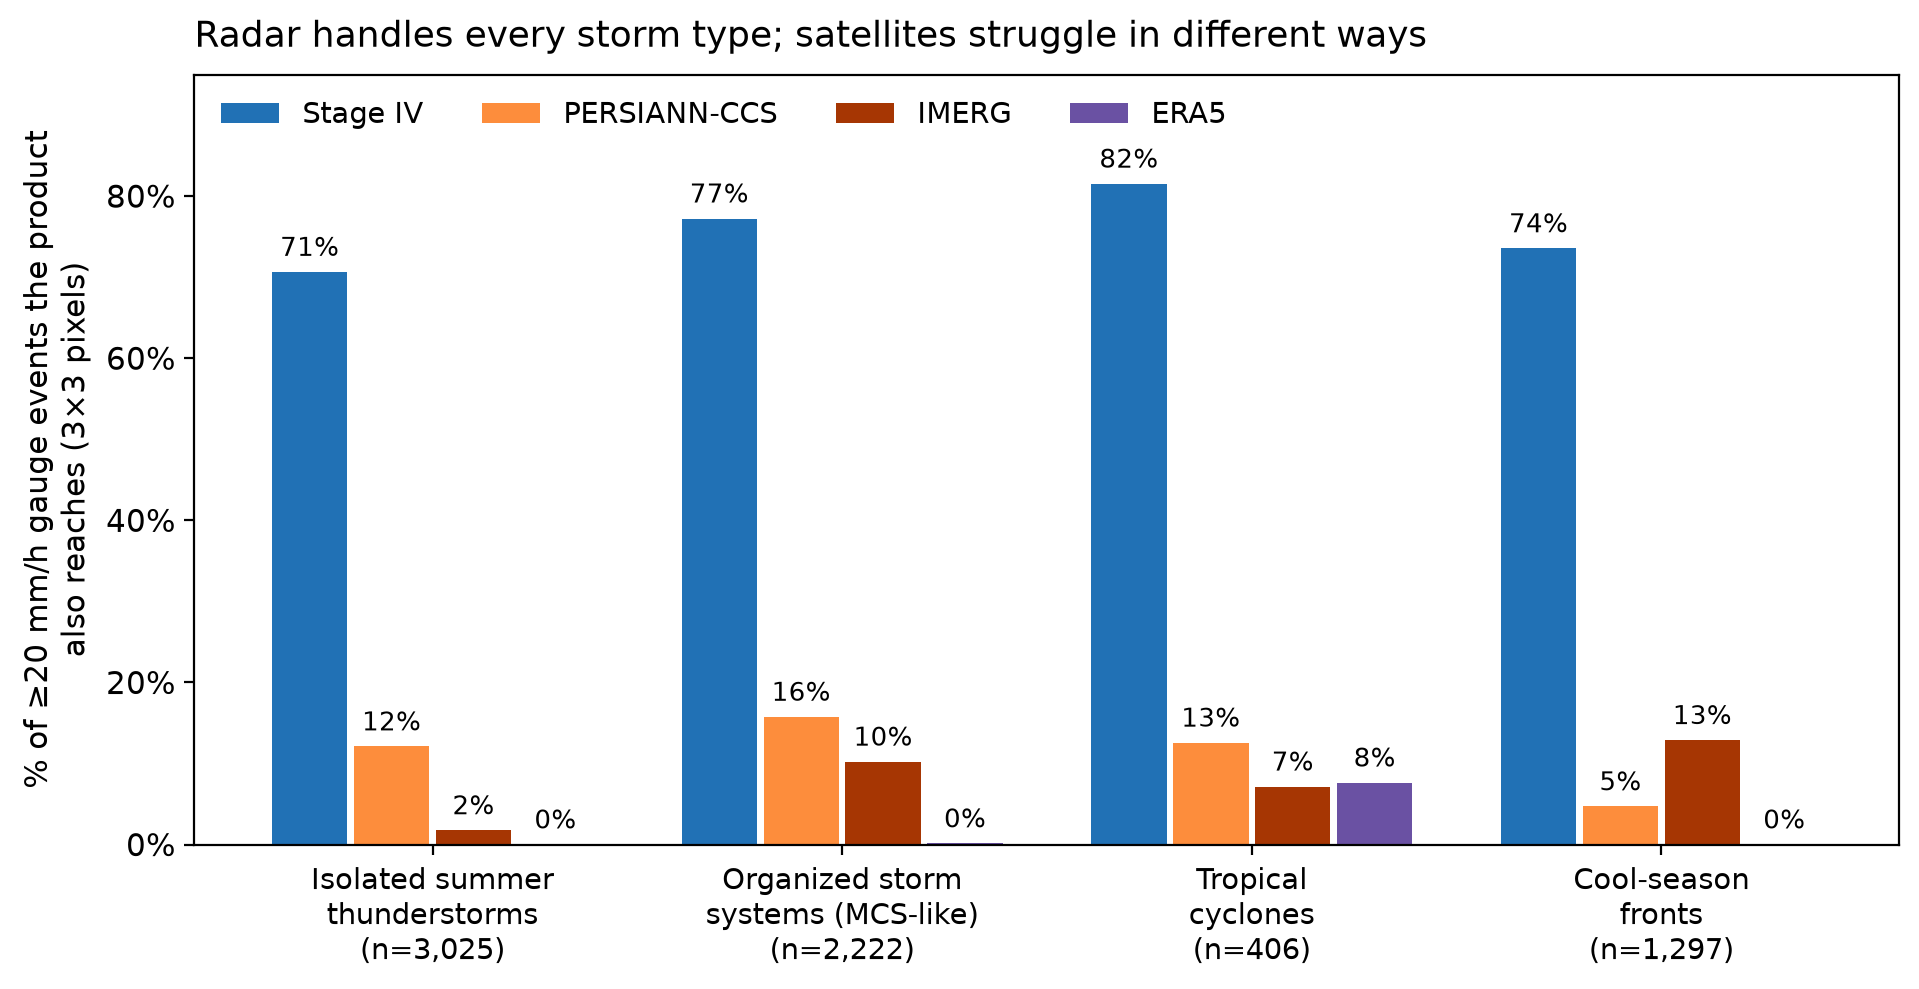

In [182]:
# [orig cell 181 | env: precip | status: ok]
ax.set_title('Radar handles every storm type; satellites struggle in different ways',loc='left',fontsize=13,pad=10)
fig3.savefig('out/li_fig3_stormtype.png',dpi=200,bbox_inches='tight')

In [183]:
# [orig cell 182 | env: precip | status: ok]
A=lambda v:'{{!artifact:'+v+'}}'
art=f"""# Satellites see the storm, not the downpour: testing 9 rainfall datasets against Florida's most extreme hours

On the afternoon of 26 May 2020, the rain gauge at Miami International Airport recorded **84.6 mm of rain in a single hour**. Streets flooded within minutes.

Gauges like that one are sparse. So when we study extreme rainfall, whether for drainage design, flood forecasting or climate change, we often turn to **gridded datasets**: radar, satellite and reanalysis products that cover every square kilometre.

That raises a simple question: **when it really pours, do these datasets see it?**

![What four rainfall products showed over the Miami gauge during the 84.6 mm hour]({A('e507eb1c-21ad-4173-a580-50f32bcfe905')})

Over the gauge, the radar products show about **50–55 mm**. The IMERG satellite product shows **5 mm**. The ERA5 reanalysis shows **3 mm**. All four "saw" the storm, but only radar came close to how hard it rained.

One storm proves nothing, so I tested it systematically.

## What I did
* **Ground truth:** 79 quality-controlled hourly rain gauges across Florida (GHCNh), 2015–2025. Each station needed at least 5 years with at least 30 complete 24-hour days.
* **Extremes:** every hour above 20, 30, 40 and 50 mm. That is thousands of events, from sea-breeze thunderstorms to hurricanes.
* **Nine gridded products:**
  * radar: MRMS and Stage IV;
  * satellite: IMERG, CMORPH, PERSIANN-CCS;
  * models/reanalyses: NLDAS-2, ERA5, MERRA-2.
* **The test:** for each extreme hour, did the product also reach the same threshold? I checked the pixel above the gauge, then 2×2, 3×3 and 4×4 groups of nearby pixels to forgive small position errors.

## What I found

![Pixel size versus detection of extreme rainfall]({A('a3f4f2e3-19e3-4167-862b-d155aabdddff')})

**1. Resolution decides almost everything.**
* Radar products (1–4 km pixels) reach the threshold in **53–66% of ≥30 mm/h events**, using a 3×3 neighborhood.
* Satellite products (4–10 km) reach it in **2–6%**.
* Global reanalyses (25–60 km) essentially never do.

**2. Satellites see the storm, but not the downpour.** Satellite products usually show rain in the right place and hour, but typically only **about 10% of the peak intensity** the gauge measured. Global reanalyses show about **2%**. A 25 km grid cell averages a 2 km thunderstorm into a drizzle.

**3. Even radar underestimates.** The best products show **62–71%** of the gauge peak at the station pixel, and they fall further short for the most intense events.

![Detection by storm type]({A('4351aad4-2329-42da-aec8-75f9ef976fd3')})

**4. Storm type matters, and each satellite fails differently.**
* IMERG catches only **2%** of isolated summer thunderstorms, the most common type of extreme in my data, but **13%** of cool-season frontal events.
* PERSIANN-CCS, which relies on infrared cloud-top temperatures, does the opposite: better in summer convection, worse in winter fronts.
* ERA5 shows skill almost only in **tropical cyclones**, where rain is driven by large-scale circulation it can resolve.

**5. The "truth" needs scrutiny too.** Radar agreed much better with airport (ASOS) gauges than with cooperative-network gauges. About half of that gap came from timing errors in the cooperative records. Before validating a product, validate your gauges.

## Why this matters
* **Infrastructure design:** intensity–duration–frequency curves built from satellite or reanalysis data would understate design storms, leaving culverts and storm drains undersized.
* **Flood modeling and risk:** low rainfall inputs mean low peak flows, smaller flood maps and underestimated risk, especially in fast-responding urban catchments.
* **Climate research:** studies of how extreme rainfall scales with temperature, or of trends in extremes, can be biased low if they rely on coarse products, and the bias changes with storm type.
* **Data-poor regions:** many places rely on satellites alone. Florida suggests those hazard estimates may be substantially low.

## Caveats
* The radar products partly ingest gauge data, so they aren't fully independent of the ground truth.
* Storm types are classified with simple proxies.
* This is one state and one decade.
* Coarse products are *expected* to smooth point extremes. The point is that they are often used for point-scale questions anyway.

## What's next
I'm interested in **storm-type-aware bias correction**, and in using high-resolution radar to build **point-to-area conversion factors**, so coarse products can be translated into the point intensities engineers actually design for.

If you work with rainfall extremes, which dataset do you trust for hourly peaks, and why? I'd love to hear from hydrologists, engineers and remote-sensing folks.

#Hydrology #ExtremeRainfall #RemoteSensing #ClimateChange #FloodRisk #StormwaterManagement #IMERG #ERA5 #Radar #Florida
"""
open('out/linkedin_article.md','w').write(art); print(len(art.split()))

729
